# Predicting Car Price

Loading, exploratory data analysis, preprocessing, model selection, and inference on a used car price dataset.

In [51]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, make_scorer

from src.preprocessing import clean_car_data, fit_impute_stats, encode_for_model, NUMERIC_IMPUTE_COLS

pd.set_option('display.max_columns', None)

## Load data

In [52]:
df = pd.read_csv('../data/raw/cars.csv')

## Exploratory data analysis (raw data)

### Shape and structure

In [53]:
print(df.shape)
df.info()

(8128, 13)
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


In [54]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


The dataset has 8,128 rows and 13 columns covering things like year, price, mileage, and engine size. A few of those columns are stored as text even though they're really numbers. Mileage and engine, for example, include their units ("23.4 kmpl", "1248 CC") right in the value, so they'll need to be cleaned up before a model can use them.

### Missing values

In [55]:
df.isna().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

Five columns are missing some values: mileage, engine, max_power, torque, and seats, each missing around 220 entries out of 8,128. The counts are close enough across all five that these are likely the same batch of incomplete listings, not unrelated gaps.

### Categorical value counts

In [56]:
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    print(df[col].value_counts())
    print()

fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64

transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64



Fuel type is mostly Diesel and Petrol, with a small number of CNG and LPG cars. CNG/LPG cars measure fuel efficiency differently (distance per kilogram of gas, not per litre), so they don't compare fairly with the rest and get removed. Most sellers are individuals rather than dealers, and manual transmission far outnumbers automatic.

### Target distribution

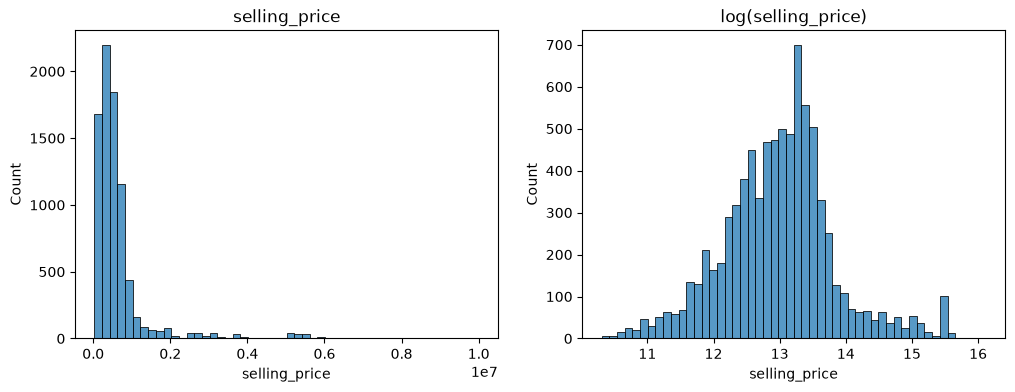

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['selling_price'], bins=50, ax=axes[0])     # type: ignore
axes[0].set_title('selling_price')
sns.histplot(np.log(df['selling_price']), bins=50, ax=axes[1])
axes[1].set_title('log(selling_price)')
plt.show()

Most cars sell for well under a million rupees, with a long tail of a few much more expensive ones stretching the scale out. Taking the logarithm of the price makes that shape more even.

### Numeric feature distributions (raw)

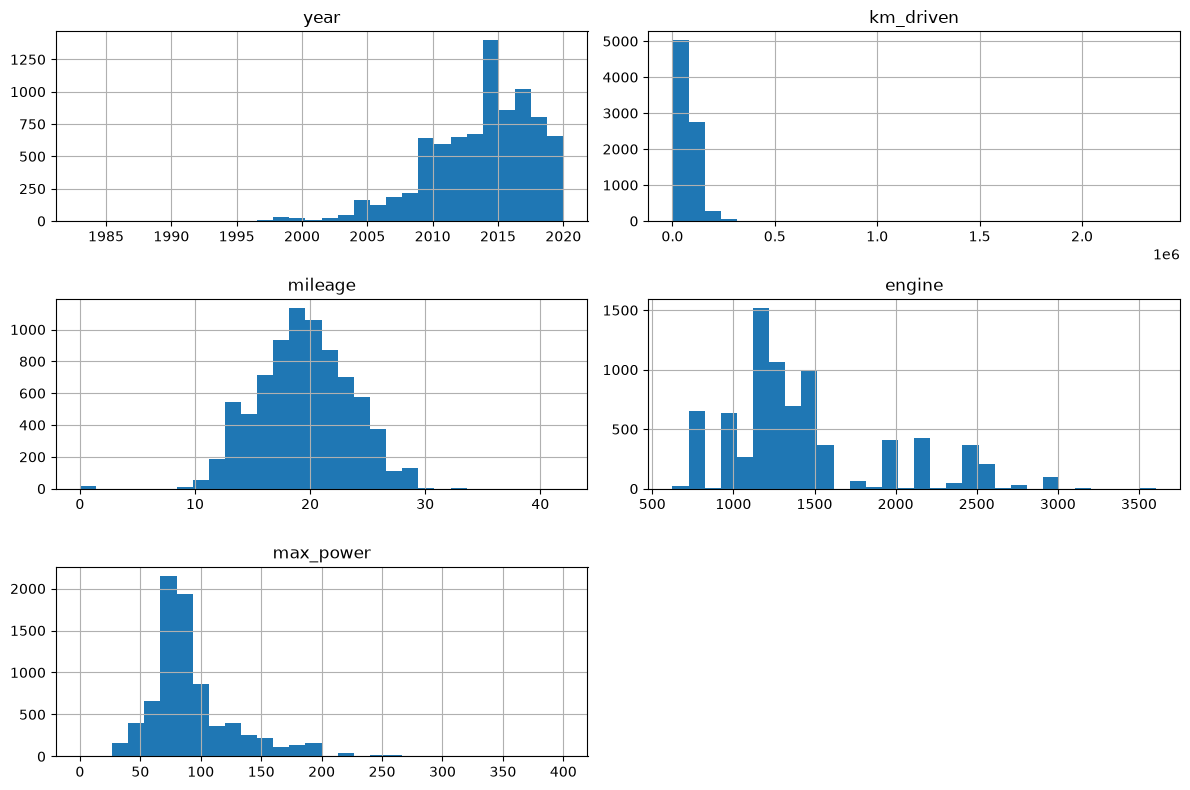

In [58]:
raw_num = pd.DataFrame({
    'year': df['year'],
    'km_driven': df['km_driven'],
    'mileage': pd.to_numeric(df['mileage'].str.split().str[0], errors='coerce'),
    'engine': pd.to_numeric(df['engine'].str.split().str[0], errors='coerce'),
    'max_power': pd.to_numeric(df['max_power'].str.split().str[0], errors='coerce'),
})
raw_num.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

These charts are drawn before any cleaning. km_driven's values bunch tightly near zero even though the x-axis stretches out past 2,000,000 which is a potential sign of outliers pulling the scale. Mileage shows a small spike right at 0 which doesn't make sense for a car actually being sold. Max_power's raw values include a handful of zeros too, though at this scale they're too few to show up as a visible spike. Year and engine look reasonable here, with no unusual spikes or gaps.

### Test Drive Car rows

In [59]:
df.groupby(df['owner'] == 'Test Drive Car')['selling_price'].describe()

,count,mean,std,min,25%,50%,75%,max
owner,,,,,,,,
False,8123.0,6.359540e+05,7.991284e+05,29999.0,254499.5,450000.0,675000.0,10000000.0
True,5.0,4.403800e+06,2.510598e+06,1350000.0,2000000.0,5923000.0,6223000.0,6523000.0


Only 5 listings are marked "Test Drive Car", priced about ₹4.4 million on average against ₹640,000 for everything else. Per the assignment's cleaning instructions, these rows are removed.

### Duplicate rows

In [60]:
df.duplicated().sum()

1202

1,202 rows (about 1 in 7) are exact duplicates, matching on every column. These are removed.

### `km_driven` outlier rows

In [61]:
df['km_driven'].describe()

count    8.128000e+03
mean     6.981951e+04
std      5.655055e+04
min      1.000000e+00
25%      3.500000e+04
50%      6.000000e+04
75%      9.800000e+04
max      2.360457e+06
Name: km_driven, dtype: float64

In [62]:
df.nsmallest(5, 'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
7913,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,209000,1,CNG,Individual,Manual,Fourth & Above Owner,15.1 km/kg,1196 CC,73 bhp,101Nm@ 3000rpm,5.0
399,Honda City i-VTEC CVT V,2018,1085000,1000,Petrol,Individual,Automatic,First Owner,18.0 kmpl,1497 CC,117.6 bhp,145Nm@ 4600rpm,5.0
2963,Maruti Swift AMT VXI,2020,654000,1000,Petrol,Individual,Automatic,First Owner,21.21 kmpl,1197 CC,81.80 bhp,113Nm@ 4200rpm,5.0
6638,Toyota Innova Crysta 2.4 ZX AT,2020,2300000,1000,Diesel,Individual,Automatic,First Owner,13.68 kmpl,2393 CC,147.51 bhp,360Nm@ 1400-2600rpm,7.0
7429,Maruti Swift LXI,2020,445000,1000,Petrol,Individual,Manual,First Owner,21.21 kmpl,1197 CC,81.80 bhp,113Nm@ 4200rpm,5.0


In [63]:
df.nlargest(10, 'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
3508,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol,Individual,Manual,Second Owner,18.9 kmpl,1061 CC,67 bhp,84Nm@ 3500rpm,5.0
3641,Maruti Wagon R VXI BS IV,2011,229999,500000,Petrol,Individual,Manual,Second Owner,18.9 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel,Individual,Manual,Second Owner,12.99 kmpl,2494 CC,100.57 bhp,200Nm@ 1400-3400rpm,7.0
5106,Mahindra Scorpio M2DI,2011,400000,475000,Diesel,Individual,Manual,Third Owner,13.5 kmpl,2179 CC,115 bhp,277.5Nm@ 1700-2200rpm,5.0
5189,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,750000,440000,Diesel,Individual,Manual,Second Owner,12.99 kmpl,2494 CC,100.6 bhp,200Nm@ 1400-3400rpm,7.0
5467,Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV,2010,950000,426000,Diesel,Individual,Manual,First Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),7.0
2272,Mahindra Bolero SLE,2010,260000,380000,Diesel,Individual,Manual,Second Owner,13.6 kmpl,2523 CC,63 bhp,180 Nm at 1440-1500rpm,7.0
7102,Toyota Innova 2.5 V Diesel 8-seater,2007,350000,376412,Diesel,Individual,Manual,Second Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),8.0


In [64]:
df[df['name'].str.contains('Hyundai i20 Asta 1.2')]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
813,Hyundai i20 Asta 1.2,2015,630000,35000,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
1485,Hyundai i20 Asta 1.2,2014,565000,70000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
2346,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
2976,Hyundai i20 Asta 1.2,2015,600000,100000,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
4034,Hyundai i20 Asta 1.2,2015,450000,60000,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
4191,Hyundai i20 Asta 1.2,2015,500000,70000,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
5499,Hyundai i20 Asta 1.2,2015,515000,120000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
6273,Hyundai i20 Asta 1.2,2018,700000,28451,Petrol,Dealer,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
6390,Hyundai i20 Asta 1.2,2013,370000,120000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0


In [65]:
df[df['name'].str.contains('Mahindra XUV500 W6 2WD')]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
793,Mahindra XUV500 W6 2WD,2014,810000,100000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
959,Mahindra XUV500 W6 2WD,2015,850000,90000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
1706,Mahindra XUV500 W6 2WD,2014,750000,80000,Diesel,Individual,Manual,Second Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
2126,Mahindra XUV500 W6 2WD,2011,475000,108000,Diesel,Dealer,Manual,First Owner,16.0 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
2857,Mahindra XUV500 W6 2WD,2014,825000,165000,Diesel,Individual,Manual,Second Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
2878,Mahindra XUV500 W6 2WD,2014,850000,120000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
3544,Mahindra XUV500 W6 2WD,2015,1050000,28000,Diesel,Individual,Manual,Second Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
3981,Mahindra XUV500 W6 2WD,2014,750000,80000,Diesel,Individual,Manual,Second Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
4114,Mahindra XUV500 W6 2WD,2016,1000000,100000,Diesel,Individual,Manual,First Owner,16.0 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0


Two listings break from the rest of the km_driven range, which otherwise runs about 35,000 to 98,000 km: a 2007 hatchback logged at 2.36 million km and a 2012 SUV at 1.5 million km. Both sold at ordinary prices, not what a genuinely worn car in that condition would fetch, pointing to a typo rather than an actual reading. Since other listings of the same models exist in the data, each value was replaced with that model's typical mileage instead of a dataset-wide average.

This fix uses the median km_driven from the whole dataset, not just the training data, which technically lets a tiny deliberate leakage to the cleaning step. The alternative was to just delete these two rows, but that throws away two real listings just because one of their columns looks wrong. Since these two values look like typos rather than genuine readings, and the fix only changes this one column (not the price we're trying to predict), this small tradeoff feels reasonable to keep.

### Zero-value rows (`mileage`, `max_power`)

In [66]:
df[pd.to_numeric(df['mileage'].str.split().str[0], errors='coerce') == 0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1172 CC,65 bhp,"9.8@ 3,000(kgm@ rpm)",5.0
785,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
1649,Hyundai Santro Xing GL,2008,105000,128000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0 kmpl,2987 CC,165 bhp,510@ 1600-2400,5.0
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,Dealer,Automatic,First Owner,0.0 kmpl,2179 CC,115 bhp,400 Nm /2000 rpm,5.0
2366,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
2725,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
4527,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0 kmpl,2987 CC,165 bhp,510@ 1600-2400,5.0
5276,Hyundai Santro Xing GL,2008,175000,40000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
5843,Volkswagen Polo GT TSI BSIV,2014,574000,28080,Petrol,Dealer,Automatic,First Owner,0.0 kmpl,1197 CC,103.25 bhp,175nm@ 1500-4100rpm,5.0


In [67]:
df[pd.to_numeric(df['max_power'].str.split().str[0], errors='coerce') == 0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
576,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
1443,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
2550,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN


A handful of listings show 0 for mileage or engine power, which isn't a real measurement for a car that's actually being sold. These are likely to be placeholder zeros standing in for missing information, so they get treated as missing values rather than genuine readings.

## Cleaning

In [68]:
df_clean = clean_car_data(df)

In [69]:
print(df_clean.shape)
df_clean.info()

(6827, 12)
<class 'pandas.DataFrame'>
RangeIndex: 6827 entries, 0 to 6826
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6827 non-null   int64  
 1   selling_price  6827 non-null   int64  
 2   km_driven      6827 non-null   int64  
 3   fuel           6827 non-null   str    
 4   seller_type    6827 non-null   str    
 5   transmission   6827 non-null   str    
 6   owner          6827 non-null   int64  
 7   mileage        6611 non-null   float64
 8   engine         6626 non-null   float64
 9   max_power      6626 non-null   float64
 10  seats          6626 non-null   float64
 11  brand          6827 non-null   object 
dtypes: float64(4), int64(4), object(1), str(3)
memory usage: 788.6+ KB


In [70]:
df_clean.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
0,2014,450000,145500,Diesel,Individual,Manual,1,23.40,1248.0,74.00,5.0,Maruti
1,2014,370000,120000,Diesel,Individual,Manual,2,21.14,1498.0,103.52,5.0,Skoda
2,2006,158000,140000,Petrol,Individual,Manual,3,17.70,1497.0,78.00,5.0,Honda
3,2010,225000,127000,Diesel,Individual,Manual,1,23.00,1396.0,90.00,5.0,Hyundai
4,2007,130000,120000,Petrol,Individual,Manual,1,16.10,1298.0,88.20,5.0,Maruti


This step applies all of the fixes above in one pass: owner history converted to numbers in order (first owner, second owner, ...), CNG/LPG listings removed, mileage/engine/power stripped of their units and converted to numbers, the brand pulled out of the full listing name, the torque column dropped, Test Drive Car listings and exact duplicates removed, and the unrealistic mileage/zero readings replaced as described above. The dataset goes from 8,128 rows and 13 columns down to 6,827 rows and 12 columns.

## Exploratory data analysis (cleaned data)

### Correlations with selling_price

In [71]:
df_clean.corr(numeric_only=True)['selling_price'].sort_values(ascending=False)

selling_price    1.000000
max_power        0.696764
engine           0.449267
year             0.438621
seats            0.163179
mileage         -0.105611
km_driven       -0.198318
owner           -0.250375
Name: selling_price, dtype: float64

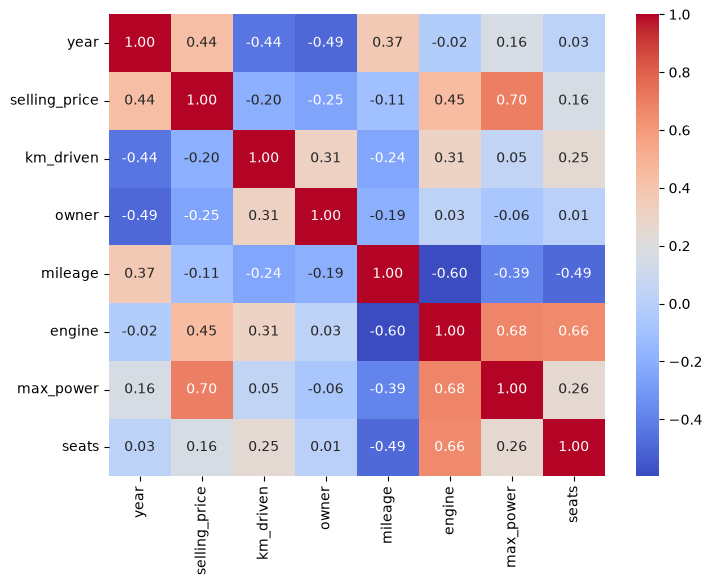

In [72]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

Engine power, engine size, and the car's year have the strongest relationship with price. More powerful, bigger-engined, newer cars sell for more, which matches expectations. Distance driven and mileage barely move the price on their own, and more previous owners tends to mean a lower price. The full table also shows engine size, power, and seat count moving together closely. A bigger engine usually comes with more power and more seats too, so these three don't each tell the model something completely different and can be said that they overlap a lot.

### Brand distribution

In [73]:
df_clean['brand'].value_counts()

brand
Maruti           2096
Hyundai          1245
Mahindra          723
Tata              646
Honda             361
Ford              361
Toyota            357
Chevrolet         214
Renault           206
Volkswagen        173
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Fiat               44
Audi               30
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Force               4
Ambassador          4
Isuzu               4
Land                3
MG                  3
Daewoo              3
Kia                 3
Lexus               1
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

Just two brands, Maruti and Hyundai, make up almost half the dataset. Many other brands have only a handful of listings, some as few as one, so predictions for those rare brands will naturally be less reliable.

### Numeric feature distributions

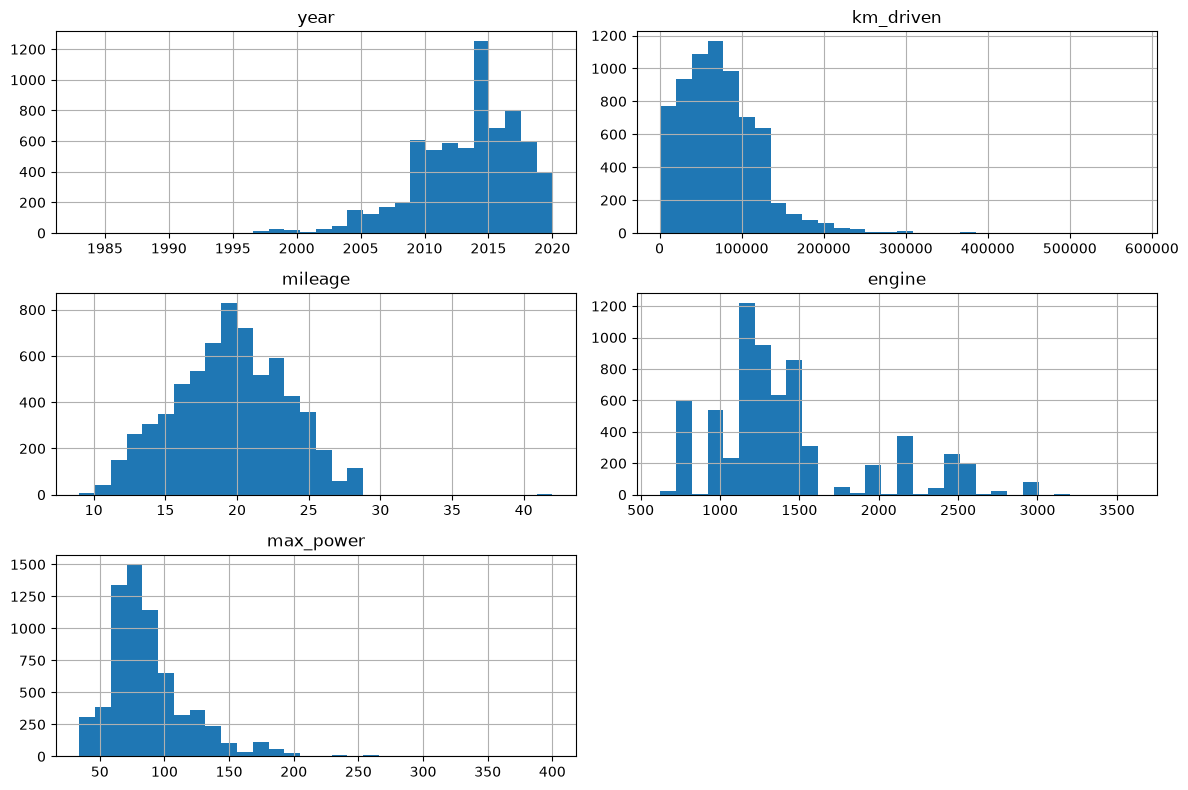

In [74]:
num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power']
df_clean[num_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

Year is weighted toward more recent cars, distance driven is bunched at the low end with a long tail of high values, mileage looks close to an even bell curve, and engine size clusters around a handful of common sizes rather than spreading out smoothly.

### `seats` distribution

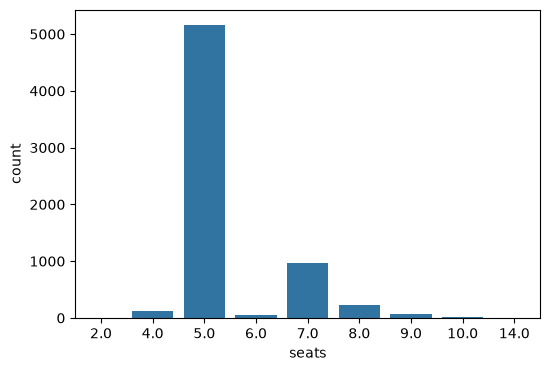

In [75]:
plt.figure(figsize=(6, 4))
sns.countplot(x='seats', data=df_clean, order=sorted(df_clean['seats'].dropna().unique()))
plt.show()

About three out of four cars seat 5 people, with 7-seaters the next most common and small numbers of everything else. Even though it's stored as a number, seat count behaves more like a category than a smoothly varying measurement.

### Missing-value pattern check

In [76]:
missing_mask = df_clean['mileage'].isna()
print('rows missing mileage/engine/seats together:',
      (df_clean['mileage'].isna() & df_clean['engine'].isna() & df_clean['seats'].isna()).sum())
print('mileage missing count:', missing_mask.sum())

rows missing mileage/engine/seats together: 201
mileage missing count: 216


In [77]:
compare = pd.concat([
    df_clean['brand'].value_counts(normalize=True).rename('overall'),
    df_clean[missing_mask]['brand'].value_counts(normalize=True).rename('missing_mileage'),
], axis=1).head(10)
compare

,overall,missing_mileage
brand,,
Maruti,0.307016,0.333333
Hyundai,0.182364,0.259259
Mahindra,0.105903,0.074074
Tata,0.094624,0.069444
Honda,0.052878,0.004630
Ford,0.052878,0.037037
Toyota,0.052292,0.152778
Chevrolet,0.031346,NaN
Renault,0.030174,NaN


In [78]:
print('overall selling_price:')
print(df_clean['selling_price'].describe())
print()
print('selling_price where mileage is missing:')
print(df_clean[missing_mask]['selling_price'].describe())

overall selling_price:
count    6.827000e+03
mean     5.179660e+05
std      5.081653e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.099990e+05
75%      6.400000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

selling_price where mileage is missing:
count    2.160000e+02
mean     2.608749e+05
std      3.442635e+05
min      3.000000e+04
25%      1.050000e+05
50%      1.820000e+05
75%      3.000000e+05
max      3.300000e+06
Name: selling_price, dtype: float64


The rows missing mileage, engine, and seat count turn out to be almost exactly the same 201 rows across all three columns which seems to be one shared batch of incomplete listings, not unrelated gaps. Certain brands, like Toyota, show up in this group far more often than their overall share of the data, and these listings tend to be noticeably cheaper: median price around ₹180,000 versus ₹410,000 overall.

### Confirming the missingness pattern (not random)

In [79]:
df_clean[missing_mask].sample(20, random_state=0)

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
6245,2005,170000,50000,Petrol,Individual,Manual,1,NaN,NaN,NaN,NaN,Maruti
1076,2008,250000,90000,Diesel,Individual,Manual,2,NaN,NaN,NaN,NaN,Maruti
2459,2002,210000,275000,Diesel,Individual,Manual,4,NaN,NaN,NaN,NaN,Toyota
5325,2009,195000,56000,Petrol,Dealer,Manual,2,NaN,NaN,NaN,NaN,Hyundai
4829,2012,275000,120000,Diesel,Individual,Manual,2,NaN,NaN,NaN,NaN,Toyota
2141,2011,295000,50000,Diesel,Individual,Manual,1,NaN,NaN,NaN,NaN,Maruti
2774,2011,375000,80000,Diesel,Individual,Manual,1,NaN,NaN,NaN,NaN,Toyota
4348,2004,80000,90000,Petrol,Individual,Automatic,2,NaN,NaN,NaN,NaN,Hyundai
135,2017,2150000,27000,Diesel,Dealer,Automatic,1,NaN,NaN,NaN,NaN,BMW
2280,2005,250000,90000,Petrol,Individual,Automatic,2,NaN,NaN,NaN,NaN,Honda


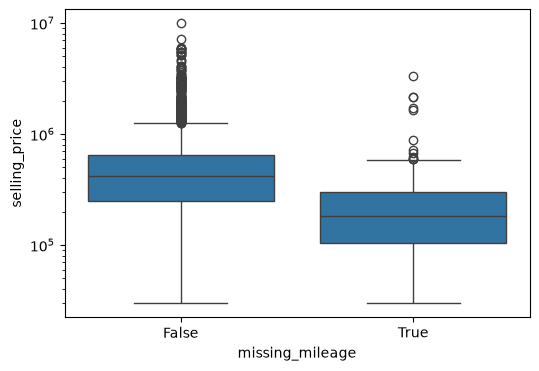

In [80]:
plot_df = df_clean.assign(missing_mileage=df_clean['mileage'].isna())
plt.figure(figsize=(6, 4))
sns.boxplot(data=plot_df, x='missing_mileage', y='selling_price')
plt.yscale('log')
plt.show()

Comparing selling price for listings with and without missing mileage confirms the pattern: prices for the missing group sit clearly lower across the board, not just in a few cases. That means filling these gaps in with a typical (median) value will slightly overstate the specs of these cheaper, older listings which will be noted as a known limitation rather than something that can be fully corrected.

### Outlier scan on remaining numeric columns

In [81]:
for col in ['mileage', 'engine', 'max_power', 'seats']:
    print(f'--- {col}: top 5 ---')
    print(df_clean.nlargest(5, col)[[col, 'brand', 'selling_price', 'year']])
    print(f'--- {col}: bottom 5 (excluding 0) ---')
    print(df_clean[df_clean[col] > 0].nsmallest(5, col)[[col, 'brand', 'selling_price', 'year']])
    print()

--- mileage: top 5 ---
     mileage   brand  selling_price  year
167     42.0   Volvo       10000000  2017
210     28.4  Maruti         700000  2018
390     28.4  Maruti         750000  2017
404     28.4  Maruti         900000  2017
467     28.4  Maruti         700000  2019
--- mileage: bottom 5 (excluding 0) ---
      mileage  brand  selling_price  year
594       9.0  Honda         275000  2004
1927      9.0  Honda         285000  2005
2569      9.0  Volvo        1950000  2016
4285      9.0  Volvo        2500000  2014
131       9.5   Jeep        4100000  2017

--- engine: top 5 ---
      engine          brand  selling_price  year
131   3604.0           Jeep        4100000  2017
5086  3498.0  Mercedes-Benz        1000000  2009
1383  3198.0           Ford        3250000  2018
1726  3198.0           Ford        2280000  2016
2891  3198.0           Ford        2100000  2016
--- engine: bottom 5 (excluding 0) ---
      engine brand  selling_price  year
357    624.0  Tata          64000  20

Checking the highest and lowest values for mileage, engine size, and power turns up nothing alarming. The extremes belong to real high-end or budget cars (a Volvo and a Mercedes at the top, small hatchbacks at the bottom) rather than data errors, so no further cleaning is needed here.

### Check with boxplots

The check above just looks at the top and bottom values one column at a time. Here we use IQR fences to flag outliers the same way for every column, instead of just checking out a sorted list. Each plot uses its own scale since the columns are so different in size, and any point outside the box's whiskers is what gets flagged.

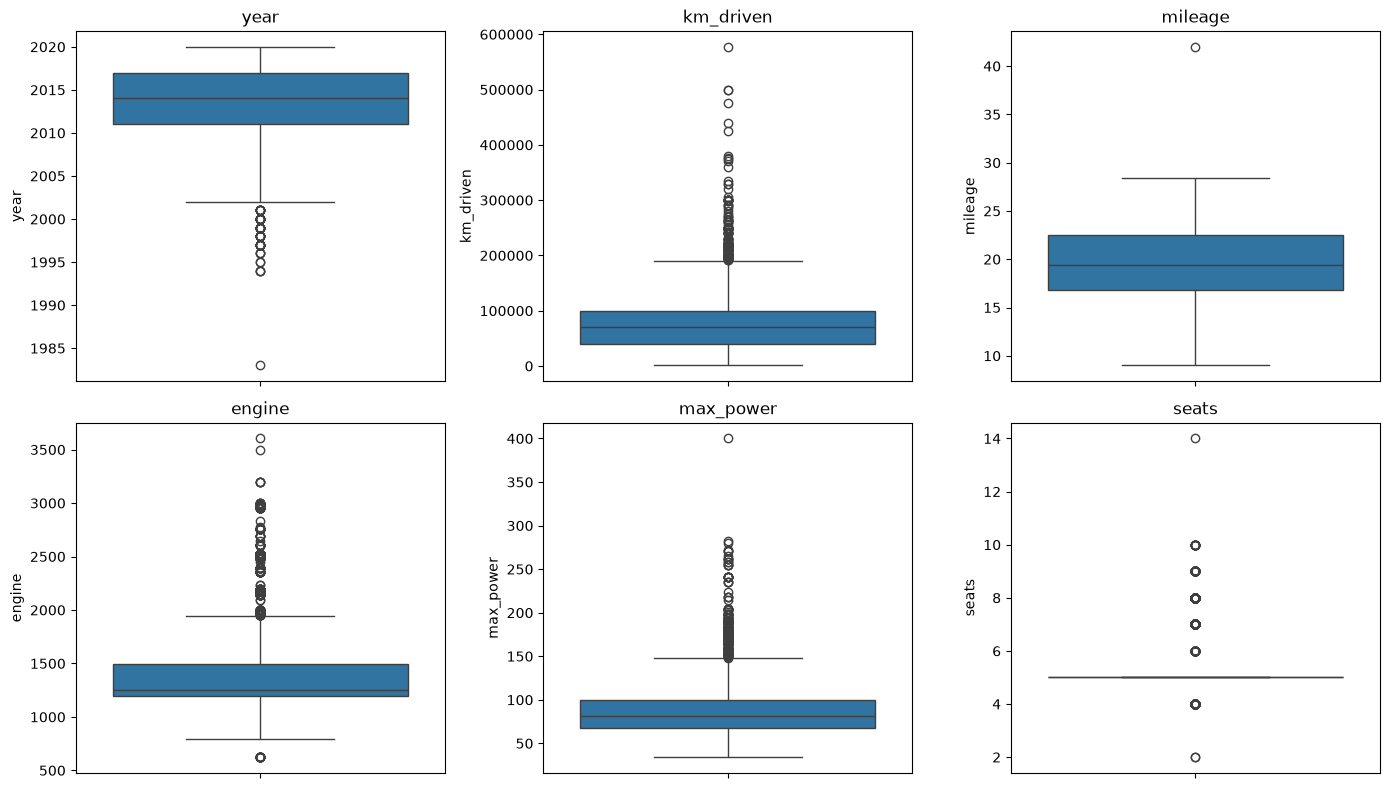

In [82]:
num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(num_cols, axes.flat):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

How many rows actually fall outside the normal range for each column, as a number instead of just a picture:

In [83]:
for col in num_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    pct = n_outliers / df_clean[col].notna().sum() * 100
    print(f'{col:10s} fence=[{lower:.2f}, {upper:.2f}]  outliers={n_outliers:5d} ({pct:.1f}%)')

year       fence=[2002.00, 2026.00]  outliers=   74 (1.1%)
km_driven  fence=[-51357.50, 190814.50]  outliers=  163 (2.4%)
mileage    fence=[8.28, 31.00]  outliers=    1 (0.0%)
engine     fence=[745.50, 1949.50]  outliers= 1207 (18.2%)
max_power  fence=[20.00, 148.00]  outliers=  302 (4.6%)
seats      fence=[5.00, 5.00]  outliers= 1459 (22.0%)


`year` and `mileage` barely flag anything (1.1% and 0.0%), matching what we already saw above. `seats` looks alarming at 22.0%, but that's just because almost every car has exactly 5 seats which makes the normal range this rule expects ends up thin, so any car with a different but completely normal seat count (like 7) gets flagged by mistake. This rule just doesn't work well on a column with so few different values, so `seats` is left alone. `engine` and `max_power` flag a much bigger share (18.2% and 4.6%) and get a closer look next. `km_driven` also needs a closer look, covered further down in its own section.

### Are the flagged `engine`/`max_power` values real errors?

Both are specs, not usage measurements, so a genuinely big car should have `engine` and `max_power` scale together, and both should scale with `selling_price`. If the flagged rows sit on the same trend as everything else, they're just big legitimate cars; a flagged row that breaks the trend (large `engine` but ordinary `max_power` or price) would be the actual red flag.

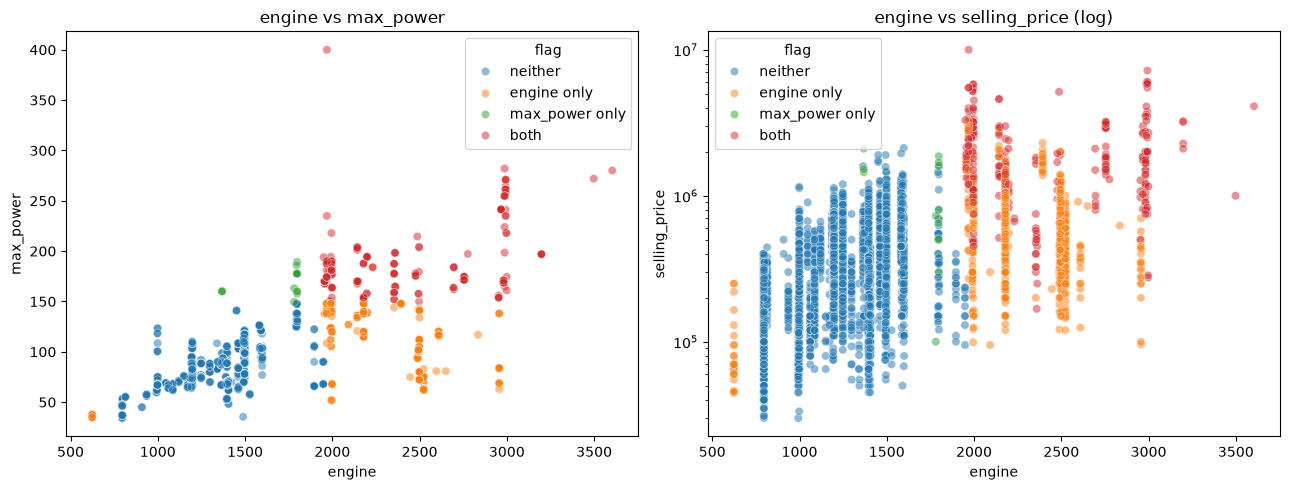

neither           5605
engine only        920
both               287
max_power only      15
Name: count, dtype: int64

In [84]:
fences = {}
for col in ['engine', 'max_power']:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fences[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

engine_flagged = (df_clean['engine'] < fences['engine'][0]) | (df_clean['engine'] > fences['engine'][1])
power_flagged = (df_clean['max_power'] < fences['max_power'][0]) | (df_clean['max_power'] > fences['max_power'][1])

flag = pd.Series('neither', index=df_clean.index)
flag[engine_flagged & ~power_flagged] = 'engine only'
flag[power_flagged & ~engine_flagged] = 'max_power only'
flag[engine_flagged & power_flagged] = 'both'

plot_df = df_clean.assign(flag=flag)
hue_order = ['neither', 'engine only', 'max_power only', 'both']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=plot_df, x='engine', y='max_power', hue='flag', hue_order=hue_order, alpha=0.5, ax=axes[0])
axes[0].set_title('engine vs max_power')

sns.scatterplot(data=plot_df, x='engine', y='selling_price', hue='flag', hue_order=hue_order, alpha=0.5, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('engine vs selling_price (log)')

plt.tight_layout()
plt.show()

flag.value_counts()

The flagged points follow the same trend as everything else (bigger engine, more power, higher price) instead of standing apart from it — they're just different kinds of cars (small hatchbacks up to SUVs and premium cars), not data errors. The 15 rows flagged only on `max_power` are a small enough group to look at directly instead of just judging from the chart.

In [85]:
df_clean.loc[flag == 'max_power only', ['brand', 'engine', 'max_power', 'selling_price', 'seats', 'fuel']]\
    .sort_values('max_power', ascending=False)

,brand,engine,max_power,selling_price,seats,fuel
363,Volkswagen,1798.0,189.30,800000,5.0,Petrol
2794,Mercedes-Benz,1796.0,186.00,400000,5.0,Petrol
3733,Mercedes-Benz,1796.0,178.00,650000,5.0,Petrol
4412,Mercedes-Benz,1796.0,178.00,500000,5.0,Petrol
3775,Skoda,1798.0,177.50,1600000,5.0,Petrol
6760,Audi,1798.0,177.50,1689999,5.0,Petrol
137,Skoda,1798.0,177.46,1864999,5.0,Petrol
3742,Audi,1781.0,163.20,730000,5.0,Petrol
39,Jeep,1368.0,160.77,2100000,5.0,Petrol
105,Volkswagen,1798.0,160.00,700000,5.0,Petrol


These are all turbocharged 1.4-1.8L petrol engines from premium/European brands (Volkswagen, Audi, Mercedes-Benz, Skoda, Jeep Compass), and their prices look normal for cars like that. Turbo engines really do get more power out of a smaller engine size, which explains why they got flagged. `engine` and `max_power` are left as they are; a small engine with high power is a real thing, not a data error, so nothing is changed here.

### `km_driven` outliers, checked the same way

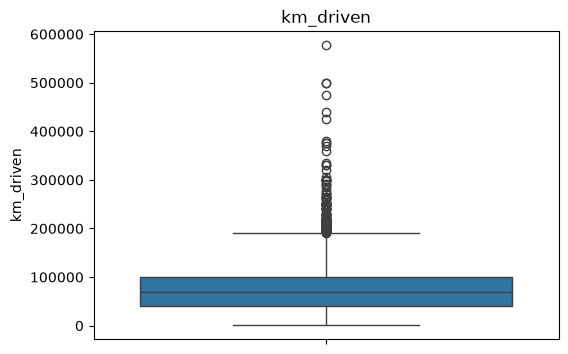

In [86]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_clean['km_driven'])
plt.title('km_driven')
plt.show()

`km_driven` has 163 cars outside the normal range found above (roughly -50,000 to 190,000 km), about 2.4% of the cleaned data. These are unusual, but this simple rule can't tell the difference between a genuinely high-mileage car and a bad reading. Nothing is removed or changed here; it's left as a known limitation instead.

### Rare-brand rows (count ≤ 11)

In [87]:
rare_brands = ['Lexus', 'Ashok', 'Opel', 'Peugeot', 'Land', 'MG', 'Daewoo', 'Kia', 'Force', 'Ambassador', 'Isuzu', 'Jaguar', 'Volvo', 'Mitsubishi']
df_clean[df_clean['brand'].isin(rare_brands)].sort_values(['brand', 'selling_price'])

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
3035,2000,75000,90000,Diesel,Individual,Manual,2,12.80,1489.0,35.50,5.0,Ambassador
4053,1994,99000,100000,Diesel,Individual,Manual,2,12.80,1995.0,52.00,5.0,Ambassador
4242,2008,122000,60000,Diesel,Individual,Manual,2,12.80,1995.0,52.00,5.0,Ambassador
6622,2008,200000,80000,Diesel,Individual,Manual,3,13.50,1995.0,52.00,5.0,Ambassador
3538,2013,300000,200000,Diesel,Individual,Manual,2,20.07,1461.0,75.00,8.0,Ashok
3560,2001,45000,137000,Petrol,Individual,Manual,1,18.50,796.0,53.00,5.0,Daewoo
1933,2000,86000,46951,Petrol,Individual,Manual,1,18.50,796.0,53.00,5.0,Daewoo
183,2000,100000,60000,Petrol,Individual,Manual,1,18.50,796.0,53.00,5.0,Daewoo
4169,2014,555000,147279,Diesel,Individual,Manual,2,17.00,2200.0,139.01,7.0,Force
3992,2018,850000,120000,Diesel,Individual,Manual,2,17.00,2650.0,80.84,7.0,Force


Brand gets turned into a separate yes/no column per brand, and some brands have only a handful of listings (several with under 5, a few with just 1). With that little data, a model has almost nothing to learn a reliable price effect from for those columns, so grouping all the rare brands into a single "other" category was considered as a way to avoid that. Looking directly at listings from the rarest brands shows why that would backfire: they span the full price range, from budget cars around ₹45,000 to a ₹10 million Volvo. Grouping them into a single "other" category would blur that real price difference, so each brand is kept separate even though some have very few listings. This will also be marked as a tradeoff worth noting as a limitation rather than something to fix.

## Train/test split

In [88]:
X = df_clean.drop(columns=['selling_price'])
y = df_clean['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Since every brand gets its own yes/no column instead of being grouped together (see above), there's a risk: if a brand shows up in the test data but was never seen while training, the model has no way to recognize it, and just treats it like it has no brand at all. Let's check if that actually happens with this split:

In [89]:
set(X_test['brand']) - set(X_train['brand'])

{'Ashok'}

One brand, Ashok, is affected. It only has a single listing in the whole dataset, so it was always going to end up entirely in one split or the other and there's no way around that without grouping rare brands together, which was already ruled out above. For this one car, the model just won't know its brand.

In [90]:
y_train_log = np.log(y_train)

## Feature encoding

In [91]:
impute_stats = fit_impute_stats(X_train)

X_train_encoded = encode_for_model(X_train, impute_stats)
feature_columns = list(X_train_encoded.columns)
X_test_encoded = encode_for_model(X_test, impute_stats, feature_columns)

assert list(X_train_encoded.columns) == list(X_test_encoded.columns)

## Model selection

### Model + hyperparameter grid

In [92]:
models = {
    "Linear Regression": (LinearRegression(), {}),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), {"max_depth": [3, 5, 8, 10, None]}),
    "Random Forest": (RandomForestRegressor(random_state=42), {"n_estimators": [100, 200], "max_depth": [None, 10, 15]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())]),
        {"knn__n_neighbors": [3, 5, 7, 10, 15]},
    ),
}

### Grid search with 5-fold cross-validation

The models are trained to predict the logged price, not the actual rupee price. That means the R² score during cross-validation would normally be measured on the logged scale, while the R² for the test set below is measured on the real rupee scale. To fix this, the scoring function below converts both back to real prices before comparing, so the cross-validation score and the test score mean the same thing.

In [93]:
def r2_on_raw_scale(y_true_log, y_pred_log):
    return r2_score(np.exp(y_true_log), np.exp(y_pred_log))

raw_scale_r2 = make_scorer(r2_on_raw_scale)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
fitted = {}

for name, (estimator, param_grid) in models.items():
    grid = GridSearchCV(estimator, param_grid, cv=kf, scoring=raw_scale_r2, n_jobs=-1)
    grid.fit(X_train_encoded, y_train_log)
    results.append({"model": name, "best_cv_r2": grid.best_score_, "best_params": grid.best_params_})
    fitted[name] = grid.best_estimator_

results_df = pd.DataFrame(results).sort_values("best_cv_r2", ascending=False)
results_df

,model,best_cv_r2,best_params
2,Random Forest,0.908914,"{'max_depth': 15, 'n_estimators': 200}"
1,Decision Tree,0.871597,{'max_depth': 10}
0,Linear Regression,0.857872,{}
3,KNN,0.805215,{'knn__n_neighbors': 3}


## Evaluation

In [94]:
eval_results = []
for name, model in fitted.items():
    pred = np.exp(model.predict(X_test_encoded))
    eval_results.append({
        "model": name,
        "test_r2": r2_score(y_test, pred),
        "test_mse": mean_squared_error(y_test, pred),
    })

eval_df = pd.DataFrame(eval_results)
comparison_df = results_df.merge(eval_df, on="model").sort_values("best_cv_r2", ascending=False)
comparison_df

,model,best_cv_r2,best_params,test_r2,test_mse
0,Random Forest,0.908914,"{'max_depth': 15, 'n_estimators': 200}",0.835678,4.559993e+10
1,Decision Tree,0.871597,{'max_depth': 10},0.776856,6.192315e+10
2,Linear Regression,0.857872,{},0.892459,2.984303e+10
3,KNN,0.805215,{'knn__n_neighbors': 3},0.740123,7.211666e+10


## Feature importance

The scaling below only applies to the number columns (`year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`); the yes/no brand/fuel/etc. columns are left alone because scaling a column divides it by how spread out its values are, and a rare brand's yes/no column barely varies at all (almost every value is 0), so scaling it makes its effect on price look artificially huge, whether or not it's real. Brands with 11 or fewer cars in training (the same rare brands flagged earlier) are also left out of the rankings below, since a price effect estimated from just a couple of cars is more noise than signal.

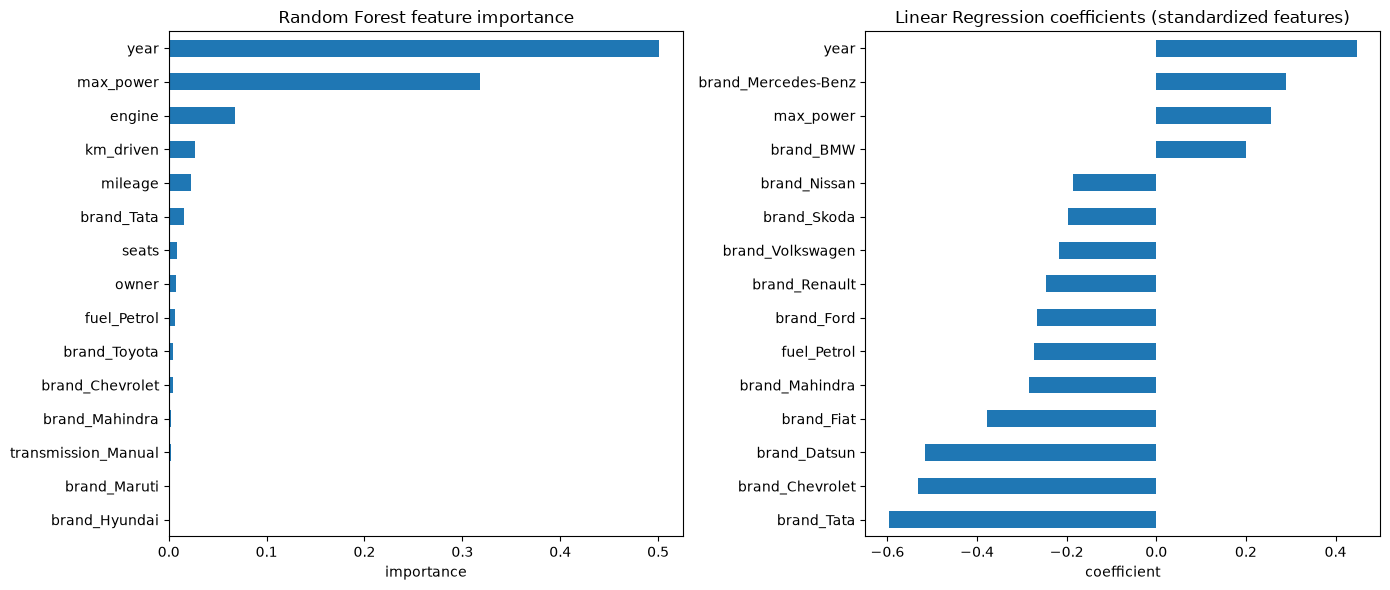

In [95]:
rare_brand_cols = [f'brand_{b}' for b in X_train['brand'].value_counts()[lambda s: s <= 11].index]

rf_importances = pd.Series(fitted["Random Forest"].feature_importances_, index=X_train_encoded.columns)
top_rf = rf_importances.sort_values(ascending=False).head(15)

X_train_scaled = X_train_encoded.copy()
X_train_scaled[NUMERIC_IMPUTE_COLS] = StandardScaler().fit_transform(X_train_encoded[NUMERIC_IMPUTE_COLS])
lr_for_coefs = LinearRegression().fit(X_train_scaled, y_train_log)
lr_coefs = pd.Series(lr_for_coefs.coef_, index=X_train_encoded.columns).drop(index=rare_brand_cols, errors='ignore')
top_lr = lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).head(15).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_rf.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Random Forest feature importance")
axes[0].set_xlabel("importance")

top_lr.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Linear Regression coefficients (standardized features)")
axes[1].set_xlabel("coefficient")

plt.tight_layout()
plt.show()

The left chart ranks each feature by how much the Random Forest actually relied on it to make predictions. The right chart shows Linear Regression's coefficients after scaling every feature to the same range, so the sizes can be compared fairly. One catch with the right chart is that turning brand into yes/no columns means one brand always has to be left out as the baseline everything else is compared against, and for brand, that baseline turned out to be Ambassador which is a brand with only two cars in the training data. That makes the brand numbers here compared against a shaky, barely-there baseline, which is why the next two charts redo the comparison against a much more common brand instead.

### Brand coefficients with a different reference brand

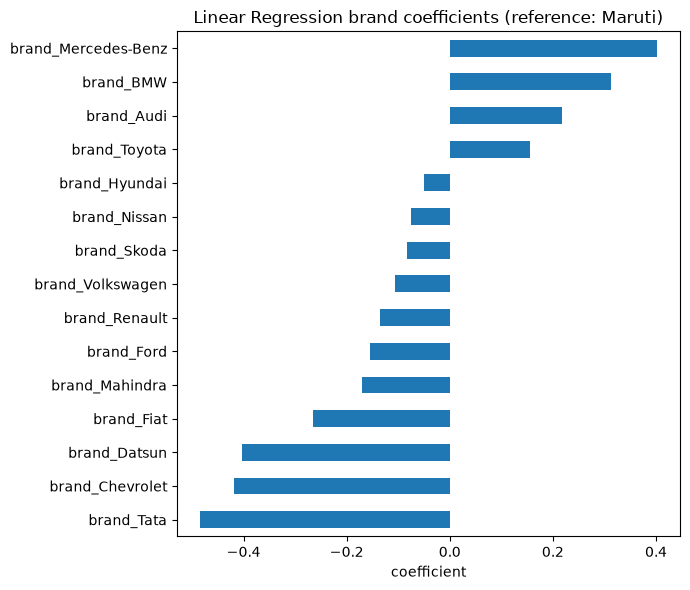

In [96]:
brand_dummies_reref = pd.get_dummies(X_train['brand']).drop(columns=['Maruti']).add_prefix('brand_')
non_brand_cols = [c for c in X_train_encoded.columns if not c.startswith('brand_')]
X_train_reref = pd.concat([X_train_encoded[non_brand_cols], brand_dummies_reref], axis=1)

X_train_reref_scaled = X_train_reref.copy()
X_train_reref_scaled[NUMERIC_IMPUTE_COLS] = StandardScaler().fit_transform(X_train_reref[NUMERIC_IMPUTE_COLS])
lr_reref = LinearRegression().fit(X_train_reref_scaled, y_train_log)
coef_reref = pd.Series(lr_reref.coef_, index=X_train_reref.columns)
brand_cols_reref = [c for c in X_train_reref.columns if c.startswith('brand_') and c not in rare_brand_cols]
top_brand_reref = coef_reref[brand_cols_reref].reindex(
    coef_reref[brand_cols_reref].abs().sort_values(ascending=False).head(15).index
)

top_brand_reref.sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Linear Regression brand coefficients (reference: Maruti)")
plt.xlabel("coefficient")
plt.tight_layout()
plt.show()

Same model as before, just re-encoded so Maruti (the most common brand) is the baseline instead of Ambassador. This only changes which brand everything else is compared against, so the model's actual predictions and R² don't change at all, only how the brand numbers read.

### All feature coefficients with the same reference brand

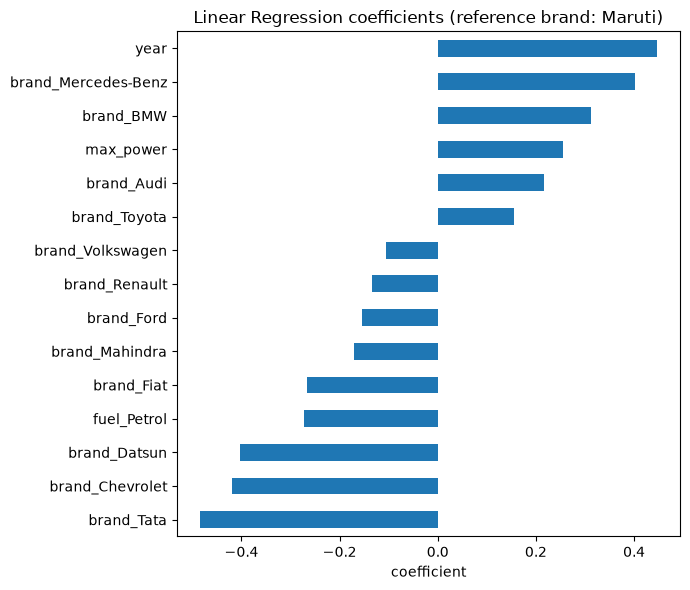

In [97]:
top_all_reref = coef_reref.drop(index=rare_brand_cols)
top_all_reref = top_all_reref.reindex(top_all_reref.abs().sort_values(ascending=False).head(15).index)

top_all_reref.sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Linear Regression coefficients (reference brand: Maruti)")
plt.xlabel("coefficient")
plt.tight_layout()
plt.show()

Same model as above, but now showing the top 15 strongest effects across every feature, not just brand, so it can be compared directly with the right-hand chart from earlier.

## Report

Year and max_power are by far the biggest drivers of price. In the Random Forest model, year alone explains about half of what the model uses to predict price, and max_power is a distant second and everything else matters much less. Engine size looked important in the correlation table earlier, but that was mostly because bigger engines usually come with more power and more seats too; once max_power is already in the model, engine size doesn't add much on its own. Distance driven and mileage barely move the price by themselves, matching what the correlation table showed.

Brand matters too. Looking only at brands with enough cars to trust the estimate (more than 11 in training), Mercedes-Benz, BMW, Audi, Toyota, and Jeep sell for more than Maruti, while Tata, Chevrolet, Datsun, Fiat, and Mahindra sell for less. This signal gets less trustworthy for the rarest brands as mentioned earlier.

Random Forest had the best cross-validation score (R² around 0.91), ahead of Decision Tree (0.87) and Linear Regression (0.86). That makes sense: Random Forest can pick up on patterns that aren't a straight line, like price changing differently depending on the car's age or engine, and averaging many trees smooths out patterns that only show up in part of the data. But on the test set, held out and never seen during training, plain Linear Regression actually did best (R² around 0.89, versus 0.84 for Random Forest). Looking closer, a handful of very expensive cars explain most of Random Forest's mistakes on the test set. Random Forest can only guess prices close to what it already saw during training, so it badly underestimates a car that costs more than anything it trained on. Linear Regression doesn't have that problem, since it can keep extending its line upward for higher prices. KNN did worst on the test set (R² around 0.74). It predicts by finding similar cars based on distance, and with so many yes/no brand columns, that distance doesn't line up well with what actually makes two cars similarly priced. Decision Tree landed in the middle on both counts, doing reasonably well but without Random Forest's averaging or Linear Regression's simplicity.


### Prediction accuracy by car age

In [ ]:
# Out-of-fold predictions: every car is priced by a model fitted without it,
# with imputation medians and feature columns refit inside each fold.
X_all = df_clean.drop(columns=['selling_price'])
y_all_log = np.log(df_clean['selling_price'])

oof_log = np.empty(len(df_clean))
for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(X_all):
    fold_stats = fit_impute_stats(X_all.iloc[train_idx])
    fold_train = encode_for_model(X_all.iloc[train_idx], fold_stats)
    fold_test = encode_for_model(X_all.iloc[test_idx], fold_stats, list(fold_train.columns))
    oof_log[test_idx] = LinearRegression().fit(fold_train, y_all_log.iloc[train_idx]).predict(fold_test)            # type: ignore

print(f'Overall out-of-fold R2 (log price): {r2_score(y_all_log, oof_log):.3f}')

rows = []
for low, high in [(1983, 1994), (1995, 1999), (2000, 2004), (2005, 2009), (2010, 2014), (2015, 2020)]:
    in_band = df_clean['year'].between(low, high)
    actual = df_clean.loc[in_band, 'selling_price']
    predicted = np.exp(oof_log[in_band.to_numpy()])
    rows.append({
        'years': f'{low}-{high}',
        'cars': int(in_band.sum()),
        'median_actual': round(actual.median()),
        'median_predicted': round(np.median(predicted)),
        'median_error_%': round(float(np.median((predicted - actual) / actual * 100))),
        'r2': round(r2_score(np.log(actual), np.log(predicted)), 2),
        'log_price_sd': round(float(np.log(actual).std()), 2),
    })

pd.DataFrame(rows).set_index('years')

Overall out-of-fold R2 (log price): 0.881


,cars,median_actual,median_predicted,median_error_%,r2,log_price_sd
years,,,,,,
1983-1994,4,109500,24702,-71,-6.49,0.78
1995-1999,42,59000,41103,-35,-0.40,0.53
2000-2004,160,80000,80602,10,0.39,0.56
2005-2009,823,150000,155956,3,0.64,0.57
2010-2014,2636,325000,326544,1,0.80,0.56
2015-2020,3162,600000,584337,-3,0.84,0.54


### Single-car brands

In [ ]:
# How the single-car brands are priced by a model that trained on them, against
# one that did not. The first fit repeats the deployed model's procedure, so the
# comparison is self-contained.
all_stats = fit_impute_stats(X_all)
X_all_encoded = encode_for_model(X_all, all_stats)
seen_log = LinearRegression().fit(X_all_encoded, y_all_log).predict(X_all_encoded)

brand_counts = df_clean['brand'].value_counts()
brand_rows = []
for brand in brand_counts[brand_counts == 1].index:
    i = df_clean.index[df_clean['brand'] == brand][0]
    brand_rows.append({
        'brand': brand,
        'year': int(df_clean.at[i, 'year']),                            # type: ignore
        'actual': round(df_clean.at[i, 'selling_price']),               # type: ignore
        'model_that_saw_it': round(float(np.exp(seen_log[i]))),
        'model_that_did_not': round(float(np.exp(oof_log[i]))),
    })

pd.DataFrame(brand_rows).set_index('brand')

,year,actual,model_that_saw_it,model_that_did_not
brand,,,,
Lexus,2019,5150000,5150000,3177406
Ashok,2013,300000,300000,446283
Opel,1998,68000,68000,59915
Peugeot,1997,57000,57000,36523


## Limitations and design decisions

This section gathers the limitations noted throughout the notebook, together with a few that only become visible once the model is used for predictions.

### What the data excludes

Data cleaning reduced the raw listings from 8,128 to 6,827. The biggest removal was 1,202 exact duplicate rows. This made up 14.8% of the file and matched across every single column. We also removed 94 CNG/LPG cars and 5 test-drive vehicles. 

### Missing values are filled with a global median, which creates bias

There are 201 listings missing `engine` size and `seats` count, and 216 missing `mileage`. These gaps occur in almost the exact same rows, suggesting a single batch of incomplete listings rather than random missing data. We filled each gap using the overall median for that column from the training data. This approach has two downsides.

First, filling in the data this way ignores the car's brand. For example, a Mercedes and a Maruti missing mileage data will both be assigned 19.4 kmpl. This number is too optimistic for one brand and too pessimistic for the other. We considered using medians specific to each brand but decided against it. Brands like Ashok, Force, and Isuzu have too few listings to calculate a reliable median. A brand-specific method would require complicated fallback rules for the exact cases where accuracy matters most.

Second, the missing data is not random. Cars with missing values usually sell for noticeably less than complete listings. By filling these gaps with the overall median, we make their features look more like an average car, which pushes their predicted prices higher. Because this bias moves in a clear and known direction, you should treat the price estimates for incomplete listings as maximum possible values.

### Outliers in distance driven were documented rather than treated

Based on a standard statistical check, 163 cars (2.4%) fell outside the normal range for `km_driven`. We chose not to alter these outliers. A manual review showed this group was mixed. Some listings had impossibly high mileage without a lower price, while others were genuinely high-mileage cars priced fairly based on wear. Any single rule to fix the unrealistic listings would have corrupted the accurate ones.

However, two rows showed distances over 1,000,000 km. During cleaning, we replaced these extreme values with the median distance for their specific car model. We calculated this median using the entire dataset rather than just the training portion. We accepted this small data leak so we could keep those two rows in the dataset.

### Brand encoding causes rare brands to be fitted unreliably

Out of 32 car brands in the dataset, 14 have 11 or fewer listings. Four of these brands (Ashok, Lexus, Opel, and Peugeot) feature exactly one car each. When a brand only has a single listing, the model creates an indicator column that perfectly memorizes that specific row instead of learning a broader pricing pattern.

As the **Single-car brands** table above shows, a model trained on these exact cars predicts their prices down to the rupee: ₹5,150,000 for the 2019 Lexus, ₹300,000 for the 2013 Ashok, ₹68,000 for the 1998 Opel, and ₹57,000 for the 1997 Peugeot. This is pure memorization rather than actual predictive accuracy. When these same cars are priced by a model that never saw them during training, the estimates change drastically. The Lexus drops to ₹3,177,406, the Ashok jumps to ₹446,283, the Opel falls to ₹59,915, and the Peugeot falls to ₹36,523. The deployed model's perfect accuracy for these brands is an illusion that would immediately fail if a user tried to price a second car from any of them.

We considered combining these rare brands into a single "Other" category to fix this, but we ultimately decided against it. These sparse brands sit at completely different ends of the market. Budget and older brands like Ambassador and Daewoo sell for roughly ₹45,000 to ₹300,000. Luxury names like Jaguar, Volvo, Lexus, and Land Rover stretch from ₹950,000 up to ₹5,500,000. Mixing these extremes together into one generic group would destroy valuable price signals instead of cleaning up statistical noise.

Our baseline encoding method creates one final issue. If a user inputs a brand the model has never seen, the system reads it as all zeros. This makes the unknown brand look exactly like the baseline brand, resulting in a confident but completely wrong price prediction without any warning or error. This is the same mechanism that produces the out-of-fold estimates above, where a held-out single-car brand is absent from the training folds entirely. To prevent it, the application only allows users to select brands that were included in the training data.

### The model is only reliable for reasonably recent cars

The **Prediction accuracy by car age** table above prices every car using a model trained on a separate segment of the data, ensuring no prediction comes from a model that has already seen the car. Accuracy drops steadily as cars get older and completely falls apart for vehicles made before 2000.

A negative R² indicates the model performs worse than just guessing the average price for that specific age group. Comparing these different age bands is fair even though they contain different numbers of cars. The spread of prices remains nearly constant across the data, meaning a dropping R² reflects a genuinely worse fit rather than just having less variation to explain.

The errors for pre-2000 cars follow a specific pattern instead of being random noise. During training, the model learned a single rule that subtracts a fixed percentage of value for every year a car ages. The model applies this rule continuously without a stopping point, causing its price predictions to drop straight through the market floor. In reality, old cars eventually level off in price because even an older working car holds some baseline value. Since the model does not know how to level off, it becomes confidently wrong in a predictable direction by pricing older cars far too low.

Because of this limitation, the application only accepts cars made in 2000 or later. The 1995 to 1999 range produces a negative R² score of -0.40, meaning the model is actively unhelpful for those years. The 2000 to 2004 bracket is the weakest accepted range, showing an R² of 0.39 and overestimating prices by about 10%. This makes the predictions usable but not excellent. Limiting the input to the year 2000 ensures the application only answers questions where the model provides a valid and realistic answer.

### Input bounds reflect physical reality, not just training data

We set the limits for numeric inputs based on what is physically possible so the system does not reject an unusual but real car. Leaving an optional field blank is the only way to indicate missing information, which then prompts the system to fill in the median value. Any entered number must fall within logical bounds. This rule prevents impossible inputs like a 0 cc engine or a typo like 12,480 cc. We made these upper limits intentionally broad to catch typos instead of acting as strict statistical cutoffs. The `year` input is the only exception to this rule. We restricted its lower limit to the point where the model stops working properly, rather than the point where older cars stop existing.

## Final model for deployment

The final deployed model is trained on the entire cleaned dataset to maximize the use of available data. The median values used to fill in missing data and the specific column structures are recalculated from this full dataset, ensuring the application perfectly matches the model's training environment.

The saved model file stores the exact lists of brands, fuel types, seller types, and transmission types present in the data. The application builds its dropdown menus directly from these lists to guarantee users can only select categories the model has actually been trained to evaluate. Additionally, the file records the dataset's seat counts and the minimum and maximum numeric values to document the specific ranges the model observed during training.

In [100]:
import joblib

X_full = df_clean.drop(columns=['selling_price'])
y_full_log = np.log(df_clean['selling_price'])

final_impute_stats = fit_impute_stats(X_full)
X_full_encoded = encode_for_model(X_full, final_impute_stats)
final_feature_columns = list(X_full_encoded.columns)

final_model = LinearRegression().fit(X_full_encoded, y_full_log)

joblib.dump(
    {
        'model': final_model,
        'impute_stats': final_impute_stats,
        'feature_columns': final_feature_columns,
        'fuel_options': sorted(X_full['fuel'].unique()),
        'seller_type_options': sorted(X_full['seller_type'].unique()),
        'transmission_options': sorted(X_full['transmission'].unique()),
        'brand_options': sorted(X_full['brand'].unique()),
        'seats_options': sorted(int(s) for s in X_full['seats'].dropna().unique()),
        'year_min': int(X_full['year'].min()),
        'year_max': int(X_full['year'].max()),
        'km_driven_min': int(X_full['km_driven'].min()),
        'km_driven_max': int(X_full['km_driven'].max()),
        'mileage_min': float(X_full['mileage'].min()),
        'mileage_max': float(X_full['mileage'].max()),
        'engine_min': float(X_full['engine'].min()),
        'engine_max': float(X_full['engine'].max()),
        'max_power_min': float(X_full['max_power'].min()),
        'max_power_max': float(X_full['max_power'].max()),
    },
    '../app/code/models/linear_model.joblib',
)

['../app/code/models/linear_model.joblib']